# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
user_id = 1610

In [12]:
features = pd.read_parquet('data/features.parquet')

In [13]:
features

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,ZMFCC10,ZMFCC11,ZMFCC12,XYCOS,XZCOS,YZCOS,XYCOR,XZCOR,YZCOR,RESULTANT
Eat_avg,0.000000,0.000000,0.000000,0.000000,0.201292,0.798652,0.000056,0.0,0.000000,0.0,...,0.238594,0.235816,0.232786,0.598902,0.996744,0.594817,-0.191686,-0.471820,-0.125553,9.347897
Eat_peak,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,NaN,...,0.297810,0.294343,0.290561,0.999991,NaN,0.999956,0.081228,-0.256704,0.189525,9.449970
Act_avg,0.043771,0.281425,0.164777,0.017486,0.200838,0.291648,0.000028,0.0,0.000028,0.0,...,0.274692,0.271494,0.268005,0.347796,0.524546,-0.031230,-0.226586,0.062980,-0.048911,9.721402
Act_peak,0.219091,0.668214,0.451855,0.138750,0.922439,1.000000,NaN,NaN,NaN,NaN,...,0.419315,0.414434,0.415597,-0.049084,0.574894,-0.251105,-0.015669,0.275879,0.186798,10.159496


### The target

In [17]:
df_eat = pd.read_parquet("data/df_eat.parquet")

In [32]:
df_act = pd.read_parquet("data/df_act.parquet")

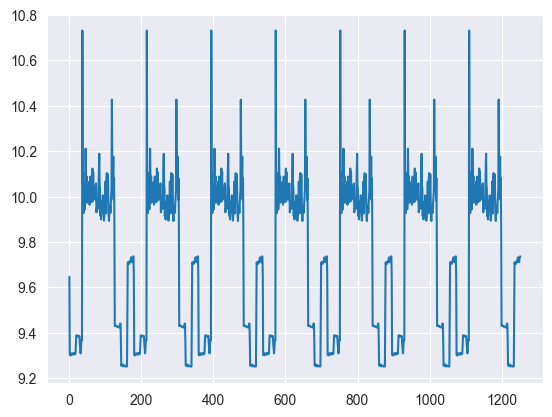

In [40]:
df_act.reset_index()['RESULTANT'].plot();

## Purely A-R Model

 We can treat the learned characteristics of the timeseries data observed to-date as informative about the structure of the unrealised future state of the same measure. 


In [59]:
## Set up a dictionary for the specification of our priors
## We set up the dictionary to specify size of the AR coefficients in
## case we want to vary the AR lags.
priors = {
    "coefs": {"mu": [10, 0.2], "sigma": [0.1, 0.1], "size": 2},
    "sigma": 8,
    "init": {"mu": 9, "sigma": 0.1, "size": 1},
}

## Initialise the model
with pm.Model() as AR:
    pass

## Define the time interval for fitting the data
t_data = list(range(len(df_eat)))
## NOTE:  Add the time interval as a mutable coordinate to the model to allow for future predictions
AR.add_coord("obs_id", t_data, mutable=True)

In [60]:
with AR:
    ## Data containers to enable prediction
    t = pm.MutableData("t", t_data, dims="obs_id")
    y = pm.MutableData("y", df_act.RESULTANT , dims="obs_id")

    # The first coefficient will be the constant term but we need to set priors for each coefficient in the AR process
    coefs = pm.Normal("coefs", priors["coefs"]["mu"], priors["coefs"]["sigma"])
    
    # We need one init variable for each lag, hence size is variable too
    init = pm.Normal.dist(
        priors["init"]["mu"], priors["init"]["sigma"], size=priors["init"]["size"]
    )
    
    sigma = pm.HalfNormal("sigma", priors["sigma"])
    
    # Steps of the AR model minus the lags required
    ar1 = pm.AR(
        "ar",
        coefs,
        sigma=sigma,
        init_dist=init,
        constant=True,
        steps=t.shape[0] - (priors["coefs"]["size"] - 1),
        dims="obs_id",
    )

    # The Likelihood
    outcome = pm.Normal("likelihood", mu=ar1, sigma=sigma, observed=y, dims="obs_id")
    

In [34]:
with AR:
    ## Sampling
    idata_ar = pm.sample_prior_predictive()
    idata_ar.extend(pm.sample(2000, random_seed=100, target_accept=0.95))
    idata_ar.extend(pm.sample_posterior_predictive(idata_ar))

Sampling: [ar, coefs, likelihood, sigma]
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [coefs, sigma, ar]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 154 seconds.
Sampling: [likelihood]


In [35]:
idata_ar

Inference data with groups:
	> posterior
	> posterior_predictive
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

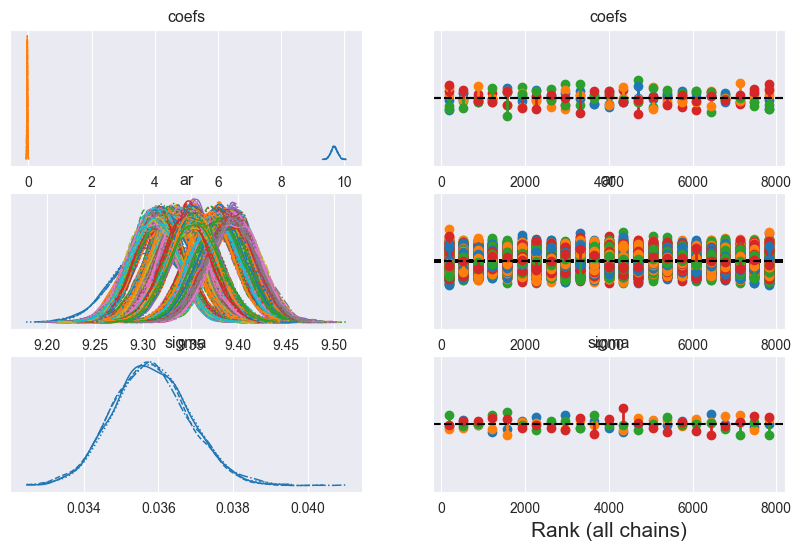

In [36]:
az.plot_trace(idata_ar, figsize=(10, 6), kind="rank_vlines");

In [37]:
az.summary(idata_ar, var_names=["~ar"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
coefs[0],9.687,0.101,9.492,9.875,0.001,0.001,8689.0,6089.0,1.0
coefs[1],-0.036,0.011,-0.056,-0.015,0.000,0.000,8703.0,6055.0,1.0
sigma,0.036,0.001,0.034,0.038,0.000,0.000,4286.0,6187.0,1.0


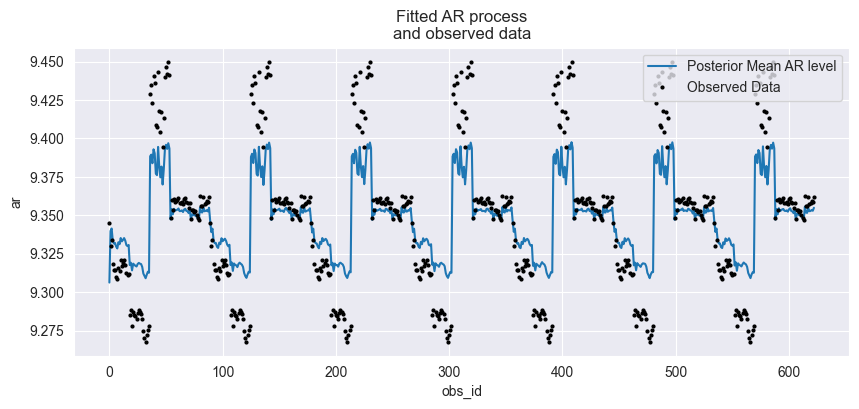

In [38]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_ar.posterior.ar.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
ax.plot(df_eat.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");

### Predictions

 - Forecast from the  posterior given the observations so far

In [61]:
prediction_length = 50
n = prediction_length - df_act.shape[0]
obs = list(range(prediction_length))

with AR:
    ## We need to have coords for the observations minus the lagged term to correctly centre the prediction step
    AR.add_coords({"obs_id_fut_1": range(df_act.RESULTANT.values.shape[0] - 1, 50, 1)})
    AR.add_coords({"obs_id_fut": range(df_act.RESULTANT.values.shape[0], 50, 1)})
    # condition on the learned values of the AR process
    # initialise the future AR process precisely at the last observed value in the AR process
    # using the special feature of the dirac delta distribution to be 0 everywhere else.
    ar1_fut = pm.AR(
        "ar1_fut",
        init_dist=pm.DiracDelta.dist(ar1[..., -1]),
        rho=coefs,
        sigma=sigma,
        constant=True,
        dims="obs_id_fut_1",
    )
    yhat_fut = pm.Normal("yhat_fut", mu=ar1_fut[1:], sigma=sigma, dims="obs_id_fut")
    # use the updated values and predict outcomes and probabilities:
    idata_preds = pm.sample_posterior_predictive(
        idata_ar, var_names=["likelihood", "yhat_fut"], predictions=True, random_seed=100
    )

Sampling: [ar1_fut, likelihood, yhat_fut]


OverflowError: can't convert negative value to unsigned int
Apply node that caused the error: Scan{scan_fn, while_loop=False, inplace=all}(-1, SetSubtensor{:stop}.0, RandomGeneratorSharedVariable(<Generator(PCG64) at 0x306EB1B60>), sigma, SpecifyShape.0, Subtensor{i}.0)
Toposort index: 9
Inputs types: [TensorType(int32, shape=()), TensorType(float64, shape=(None,)), RandomGeneratorType, TensorType(float64, shape=()), TensorType(float64, shape=(1,)), TensorType(float64, shape=())]
Inputs shapes: [(), (0,), 'No shapes', (), (1,), ()]
Inputs strides: [(), (0,), 'No strides', (), (-8,), ()]
Inputs values: [array(-1, dtype=int32), array([], dtype=float64), Generator(PCG64) at 0x306EB1B60, array(0.03688665), array([-0.04475368]), array(9.76799348)]
Outputs clients: [[Subtensor{start:}(Scan{scan_fn, while_loop=False, inplace=all}.0, 1)], ['output']]

HINT: Re-running with most PyTensor optimizations disabled could provide a back-trace showing when this node was created. This can be done by se

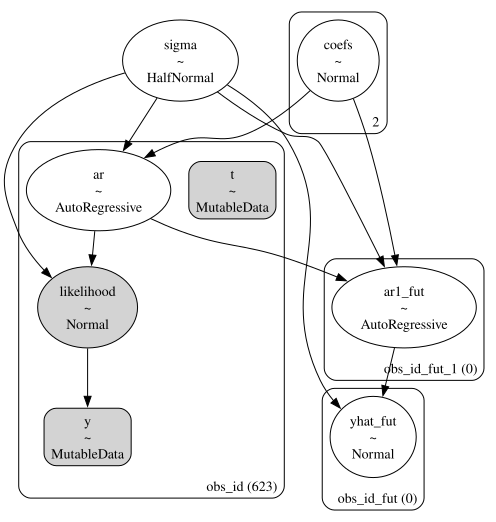

In [52]:
pm.model_to_graphviz(AR)